# Comparator sizing (Fig. 15)

Hammerschmied & Huang latched comparator: NMOS input pair T1/T2, PMOS latch/loads T3/T4 (lvt), reset switch T9 (lvt), NMOS latch T5/T6.

In [1]:
import math
import matplotlib.pyplot as plt
from sarlib import specs as S
from sarlib.specs import tech as T
from sarlib.gmid import nmos, pmos_lvt, size, vgs_at, device_table
from sarlib.analysis import Report

c = S.comparator
rep = Report()
sz = lambda mos, key, ID, VDS, VSB=0.0: size(mos, ID, c.GMID[key], c.LEN[key], VDS, VSB)

## Loads and a/b reset level

In reset T9 shorts a and b, so T3/T4 are diode-connected and a/b sit at VDD - VSG(T3).

In [2]:
I_LOAD = c.I_TAIL / 2
vsg = 0.7
for _ in range(10):
    ld = sz(pmos_lvt, 'load', I_LOAD, vsg)
    if abs(ld['VGS'] - vsg) < 1e-3:
        break
    vsg = ld['VGS']
V_AB = S.VDD - ld['VGS']
print(f'V_AB = {V_AB:.3f} V')

V_AB = 1.135 V


## Input pair and tail

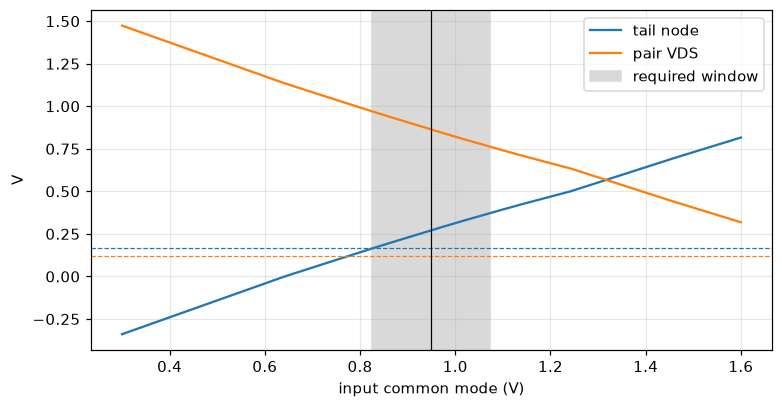

In [3]:
VCM = S.VCM_CMP
vt = 0.5
for _ in range(20):
    pr = sz(nmos, 'pair', I_LOAD, V_AB - vt, vt)
    vt, done = VCM - pr['VGS'], abs(VCM - pr['VGS'] - vt) < 1e-3
    if done:
        break
pr = sz(nmos, 'pair', I_LOAD, V_AB - vt, vt)
tl = sz(nmos, 'tail', c.I_TAIL, max(vt, 0.1))

def tail_node(vcm):
    v = 0.5
    for _ in range(30):
        n = vcm - vgs_at(nmos, I_LOAD, pr['W'], pr['L'], max(V_AB - v, 0.1), v)
        if abs(n - v) < 1e-4:
            return n
        v = n
    return v

cms = [i / 100 for i in range(20, 161)]
tails = [tail_node(v) for v in cms]
ok_cm = [v for v, t in zip(cms, tails) if t >= tl['VDSAT'] + c.MARGIN and V_AB - t >= pr['VDSAT'] + c.MARGIN]
cm_lo, cm_hi = min(ok_cm), max(ok_cm)
rep.check('common-mode range covered', f'{cm_lo:.2f}-{cm_hi:.2f} V', f'{c.CM_RANGE[0]:.3f}-{c.CM_RANGE[1]:.3f} V',
          cm_lo <= c.CM_RANGE[0] + 1e-9 and cm_hi >= c.CM_RANGE[1] - 1e-9)

fig, ax = plt.subplots(figsize=(7, 3.6))
sel = [i for i, v in enumerate(cms) if v >= 0.3]
ax.plot([cms[i] for i in sel], [tails[i] for i in sel], label='tail node')
ax.plot([cms[i] for i in sel], [V_AB - tails[i] for i in sel], label='pair VDS')
ax.axhline(tl['VDSAT'] + c.MARGIN, ls='--', c='C0', lw=0.8)
ax.axhline(pr['VDSAT'] + c.MARGIN, ls='--', c='C1', lw=0.8)
ax.axvspan(*c.CM_RANGE, color='0.85', label='required window')
ax.axvline(VCM, c='k', lw=0.8)
ax.set_xlabel('input common mode (V)'); ax.set_ylabel('V'); ax.legend()
plt.show()

## NMOS latch and device table

In [4]:
gm1, gm3 = pr['gm'], ld['gm']
lt = sz(nmos, 'latch', c.GM5_OVER_GM3 * gm3 / c.GMID['latch'], 0.5 * S.VDD)
ratio = c.I_TAIL / c.I_REF
wr = tl['W'] / ratio
rep.check('lvt pfet minimum L (T3/T4, T9)', f"{min(ld['L'], c.SW['T9'][1]):.2f} um", f'>= {T.L_MIN_PLVT:g} um',
          min(ld['L'], c.SW['T9'][1]) >= T.L_MIN_PLVT - 1e-9)
print(f"tail node at {VCM:g} V: {vt:.3f} V; gm1/gm3 = {gm1 / gm3:.2f}; mirror reference W = {wr:.2f} um ({ratio:g}:1)")
device_table([('T1/T2 pair', pr), ('T3/T4 load', ld), ('M0 tail', tl), ('T5/T6 latch', lt)])

tail node at 0.949 V: 0.270 V; gm1/gm3 = 2.86; mirror reference W = 0.55 um (8:1)


,ID,W,L,gmid,VGS,VDS,VDSAT,gm,gds
T1/T2 pair,4.0,4.151,0.5,20,0.679,0.865,0.069,80.0,0.614
T3/T4 load,4.0,1.051,0.5,7,0.665,0.665,0.237,28.0,1.323
M0 tail,8.0,4.361,1.0,14,0.699,0.270,0.117,112.0,1.621
T5/T6 latch,3.5,0.493,1.0,8,0.821,0.900,0.201,28.0,0.199


## Capacitances, speed, noise

In [5]:
cj = lambda W: T.CJ_FF_UM * W
cgd = lambda W: T.COV_FF_UM * W
cgg = lambda W, L: c.CGG_FACTOR * T.COX_FF_UM2 * W * L + 2 * T.COV_FF_UM * W
C_AB = (cj(pr['W']) + cgd(pr['W']) + cj(ld['W']) + cgd(ld['W']) + cgg(ld['W'], ld['L'])
        + cj(c.SW['T9'][0]) + cj(c.SW['T78'][0]) + c.C_WIRE_FF)
C_IN = cgg(pr['W'], pr['L']) + 2 * cgd(pr['W'])
C_Q = c.C_Q_LOAD_FF + cj(lt['W']) + cgg(lt['W'], lt['L']) + cj(c.SW['T1011'][0]) + cj(c.SW['T78'][0])

def decision_time(g1, g3, g5, c_ab, c_q):
    tau = c_ab * 1e-15 / (g3 * 1e-6)
    return tau, tau * math.log(1 + c.V_CONNECT * g3 / (g1 * c.VIN_MIN)), c.N_TAU_LATCH * c_q * 1e-15 / (g5 * 1e-6)

tau, t1, t2 = decision_time(gm1, gm3, lt['gm'], C_AB, C_Q)
d = c.GM_DERATE
_, t1c, t2c = decision_time(d * gm1, d * gm3, d * lt['gm'], c.C_DERATE * C_AB, c.C_DERATE * C_Q)
t_dec = 1e9 * (t1c + t2c)

kT = 1.380649e-23 * S.TEMP
v_sw = math.sqrt(2 * kT / (C_AB * 1e-15)) * gm3 / gm1
v_th2 = 4 * kT * T.GAMMA_N * (gm1 + gm3) * 1e-6 / ((gm1 * 1e-6) ** 2 * tau)
noise_mv = 1e3 * math.sqrt(v_sw ** 2 + v_th2)

print(f'C_ab = {C_AB:.1f} fF, C_Q = {C_Q:.1f} fF, C_in = {C_IN:.1f} fF')
print(f'tau = {1e9 * tau:.2f} ns; decision at {1e3 * c.VIN_MIN:.2f} mV: {1e9 * (t1 + t2):.2f} ns nominal, {t_dec:.2f} ns derated')
print(f'noise: reset kT/C {1e3 * v_sw:.2f} mV, thermal {1e3 * math.sqrt(v_th2):.2f} mV, total {noise_mv:.2f} mV rms')
rep.limit('decision time, derated', t_dec, '{:.1f} ns', c.SPECS['t_dec_ns_max'], '<=', 'ns')
rep.limit('input noise', noise_mv, '{:.2f} mV', c.SPECS['noise_mv_max'], '<=', 'mV')
rep.limit('input capacitance', C_IN, '{:.1f} fF', c.SPECS['c_in_ff_max'], '<=', 'fF')

C_ab = 10.0 fF, C_Q = 16.6 fF, C_in = 13.7 fF
tau = 0.36 ns; decision at 5.45 mV: 2.68 ns nominal, 4.21 ns derated
noise: reset kT/C 0.32 mV, thermal 0.74 mV, total 0.81 mV rms


## Offset and kickback

In [6]:
w9, l9 = c.SW['T9']
vov9 = V_AB - T.VTH_P_LVT
s_pair = T.AVT_N / math.sqrt(pr['W'] * pr['L'])
s_load = gm3 / gm1 * T.AVT_P / math.sqrt(ld['W'] * ld['L'])
s_inj = 1e3 * c.INJ_MISMATCH * 0.5 * w9 * l9 * T.COX_FF_UM2 * vov9 / C_AB * gm3 / gm1
s_tot = math.sqrt(s_pair ** 2 + s_load ** 2 + s_inj ** 2)
print(f'1 sigma offset: pair {s_pair:.2f}, loads {s_load:.2f}, T9 injection {s_inj:.2f}, total {s_tot:.2f} mV')
rep.limit('random offset, 3 sigma', 3 * s_tot, '{:.1f} mV', c.SPECS['offset_3sigma_mv_max'], '<=', 'mV')

C_NODE_FF = 1e15 * S.C_NODE
tau_node = S.R_NODE * S.C_NODE
loop = cgd(pr['W']) / C_NODE_FF * gm1 / gm3
peak_mv = 1e3 * cgd(pr['W']) * 1.2 / C_NODE_FF
resid_lsb = peak_mv * math.exp(-(c.T_EVAL - c.T_STEP) / tau_node) / (1e3 * S.V_LSB_CMP)
print(f'peak kick {peak_mv:.1f} mV, residual at next strobe {resid_lsb:.4f} LSB; '
      f'C_in adds up to {1e9 * S.SETTLE_NODE * C_IN / C_NODE_FF:.1f} ns of node settling')
rep.limit('kick loop factor', loop, '{:.3f}', c.SPECS['kick_loop_max'], '<=')
rep.limit('residual kick at the next step', resid_lsb, '{:.4f} LSB', c.SPECS['kick_resid_lsb_max'], '<=', 'LSB')

1 sigma offset: pair 3.47, loads 2.41, T9 injection 1.84, total 4.61 mV
peak kick 14.9 mV, residual at next strobe 0.0000 LSB; C_in adds up to 7.3 ns of node settling


## Reset and power

In [7]:
ron = lambda mucox, W, L, vov: 1e3 / (mucox * (W / L) * vov)        # kohm
r9 = ron(T.MUCOX_P, w9, l9, vov9)
r1011 = ron(T.MUCOX_N, *c.SW['T1011'], S.VDD - T.VTH_N)
n_tau_rst = (c.T_EVAL - c.T_STEP) * 1e9 / (r9 * C_AB * 1e-3)
print(f'T9 R_on {r9:.1f} kohm, T10/T11 R_on {r1011:.1f} kohm (Q collapse tau {r1011 * C_Q * 1e-3:.3f} ns)')
print(f'static {S.VDD * (c.I_TAIL + c.I_REF):.1f} uW, dynamic {(C_AB + C_Q) * S.VDD ** 2 * 1e-3:.2f} pJ per decision')
rep.check('T9 can turn on (Vsg - |Vth|)', f'{vov9:.2f} V', '> 0.05 V', vov9 > 0.05)
rep.check('reset is monostable (g_on(T9) >= 3 gm3)', f'{1e3 / r9:.0f} vs {3 * gm3:.0f} uS', '>= 3 gm3', 1e3 / r9 >= 3 * gm3)
rep.check('reset of a/b', f'{n_tau_rst:.0f} tau', '>= 15 tau', n_tau_rst >= 15)

T9 R_on 8.9 kohm, T10/T11 R_on 0.7 kohm (Q collapse tau 0.011 ns)
static 16.2 uW, dynamic 0.09 pJ per decision


## Summary

In [8]:
print(f"wp={pr['W']:.2f} lp={pr['L']:.2f} wl={ld['W']:.2f} ll={ld['L']:.2f} wnn={lt['W']:.2f} lnn={lt['L']:.2f} "
      f"w9={w9:g} l9={l9:g} w78={c.SW['T78'][0]:g} l78={c.SW['T78'][1]:g} w1011={c.SW['T1011'][0]:g} l1011={c.SW['T1011'][1]:g} "
      f"wr={wr:.2f} lt={tl['L']:g} itail_ratio={ratio:g} iref={c.I_REF:g}u")
rep.table()

wp=4.15 lp=0.50 wl=1.05 ll=0.50 wnn=0.49 lnn=1.00 w9=1 l9=0.35 w78=1 l78=0.15 w1011=1 l1011=0.15 wr=0.55 lt=1 itail_ratio=8 iref=1u


,check,value,spec,result
0,common-mode range covered,0.83-1.60 V,0.825-1.073 V,FAIL
1,"lvt pfet minimum L (T3/T4, T9)",0.35 um,>= 0.35 um,PASS
2,"decision time, derated",4.2 ns,<= 15 ns,PASS
3,input noise,0.81 mV,<= 2.725 mV,PASS
4,input capacitance,13.7 fF,<= 15 fF,PASS
5,"random offset, 3 sigma",13.8 mV,<= 5 mV,FAIL
6,kick loop factor,0.036,<= 0.2,PASS
7,residual kick at the next step,0.0000 LSB,<= 0.1 LSB,PASS
8,T9 can turn on (Vsg - |Vth|),0.71 V,> 0.05 V,PASS
9,reset is monostable (g_on(T9) >= 3 gm3),112 vs 84 uS,>= 3 gm3,PASS
